In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienie stylu wykresów (będą dobrze wyglądać w sprawozdaniu)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Wczytanie zbioru danych (ścieżka względna z folderu notebooks/)
df = pd.read_csv("../data/tabular/healthcare-dataset-stroke-data.csv")

print(f"Wymiary zbioru: {df.shape[0]} wierszy, {df.shape[1]} kolumn")
display(df.head())

Wymiary zbioru: 5110 wierszy, 12 kolumn


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print("--- Informacje o kolumnach i typach danych ---")
df.info()

print("\n--- Liczba brakujących wartości (NaN) ---")
missing = df.isnull().sum()
print(missing[missing > 0])

print(f"\nLiczba zduplikowanych wierszy: {df.duplicated().sum()}")

--- Informacje o kolumnach i typach danych ---
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

--- Liczba brakujących wartości (NaN) ---
bmi    201
dtype: int64

Liczba zduplikowanych wierszy: 0


In [4]:
# Statystyki dla cech numerycznych (bez ID)
display(df.drop(columns=["id"]).describe().round(2))

# Rozkład wartości dla zmiennych tekstowych (kategorycznych)
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for col in cat_cols:
    print(f"\n--- Rozkład kategorii: {col} ---")
    print(df[col].value_counts())

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,43.23,0.1,0.05,106.15,28.89,0.05
std,22.61,0.3,0.23,45.28,7.85,0.22
min,0.08,0.0,0.00,55.12,10.30,0.00
25%,25.00,0.0,0.00,77.24,23.50,0.00
50%,45.00,0.0,0.00,91.88,28.10,0.00
75%,61.00,0.0,0.00,114.09,33.10,0.00
max,82.00,1.0,1.00,271.74,97.60,1.00



--- Rozkład kategorii: gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

--- Rozkład kategorii: ever_married ---
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

--- Rozkład kategorii: work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

--- Rozkład kategorii: Residence_type ---
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

--- Rozkład kategorii: smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


C:\Users\Bartek\AppData\Local\Temp\ipykernel_5512\1339809505.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="stroke", ax=axes[0], palette="Set2")
C:\Users\Bartek\AppData\Local\Temp\ipykernel_5512\1339809505.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="stroke", y="avg_glucose_level", ax=axes[2], palette="Set2")


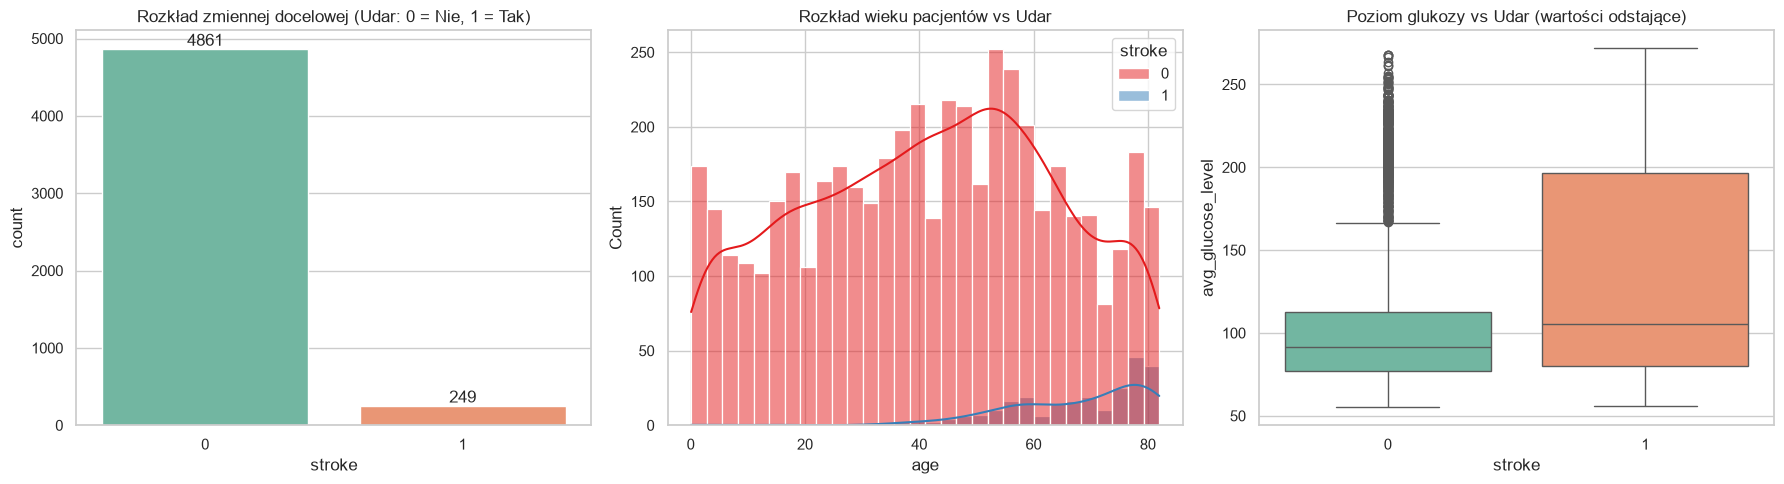

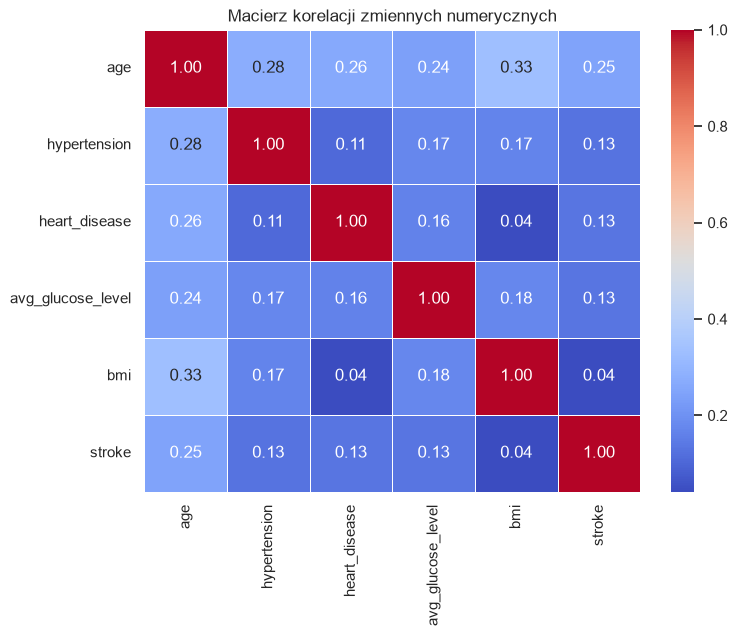

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Rozkład zmiennej docelowej (stroke)
sns.countplot(data=df, x="stroke", ax=axes[0], palette="Set2")
axes[0].set_title("Rozkład zmiennej docelowej (Udar: 0 = Nie, 1 = Tak)")
for container in axes[0].containers:
    axes[0].bar_label(container)

# 2. Rozkład wieku względem wystąpienia udaru
sns.histplot(data=df, x="age", hue="stroke", kde=True, bins=30, ax=axes[1], palette="Set1")
axes[1].set_title("Rozkład wieku pacjentów vs Udar")

# 3. Rozkład poziomu glukozy (wykres pudełkowy - wyłapuje wartości odstające)
sns.boxplot(data=df, x="stroke", y="avg_glucose_level", ax=axes[2], palette="Set2")
axes[2].set_title("Poziom glukozy vs Udar (wartości odstające)")

plt.tight_layout()
plt.show()

# 4. Macierz korelacji zmiennych numerycznych
plt.figure(figsize=(8, 6))
numeric_df = df.drop(columns=["id"]).select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Macierz korelacji zmiennych numerycznych")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Kopia danych i usunięcie kolumny 'id'
df_clean = df.drop(columns=["id"]).copy()

# 2. Uzupełnienie braków w 'bmi' medianą
df_clean["bmi"] = df_clean["bmi"].fillna(df_clean["bmi"].median())

# 3. Usunięcie pojedynczego rekordu 'Other' w 'gender' (dla czystości kodowania)
df_clean = df_clean[df_clean["gender"] != "Other"]

# 4. Zamiana zmiennych kategorycznych na liczby (One-Hot Encoding)
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)

print(f"Wymiary danych po kodowaniu: {df_encoded.shape[0]} wierszy, {df_encoded.shape[1]} kolumn")

# 5. Podział na cechy (X) i zmienną docelową (y)
X = df_encoded.drop(columns=["stroke"])
y = df_encoded["stroke"]

# 6. Podział na zbiór treningowy (80%) i testowy (20%) z zachowaniem proporcji klas (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 7. Standaryzacja cech numerycznych (dopasowana TYLKO do zbioru treningowego!)
scaler = StandardScaler()
num_cols = ["age", "avg_glucose_level", "bmi"]

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Zbiór treningowy: {X_train.shape}, Zbiór testowy: {X_test.shape}")
print(f"Liczba udarów w zbiorze testowym: {y_test.sum()} z {len(y_test)} pacjentów")

Wymiary danych po kodowaniu: 5109 wierszy, 16 kolumn
Zbiór treningowy: (4087, 15), Zbiór testowy: (1022, 15)
Liczba udarów w zbiorze testowym: 50 z 1022 pacjentów


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from sklearn.utils.class_weight import compute_class_weight

# Ustawienie ziarna losowości dla powtarzalności wyników
tf.random.set_seed(42)

# 1. Obliczenie wag klas (rekompensata za silne niezbalansowanie 95% vs 5%)
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print("Wagi klas przekazane do sieci:", class_weights)

# 2. Budowa płytkiej sieci neuronowej (MLP)
model_mlp = Sequential([
    Input(shape=(X_train.shape[1],)),       # Warstwa wejściowa (15 cech)
    Dense(32, activation="relu"),           # 1. warstwa ukryta
    Dropout(0.2),                           # Regularyzacja przeciw przeuczeniu
    Dense(16, activation="relu"),           # 2. warstwa ukryta
    Dense(1, activation="sigmoid")          # Wyjście binarne (prawdopodobieństwo udaru)
])

model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

model_mlp.summary()

# 3. Trening sieci
history = model_mlp.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

Wagi klas przekazane do sieci: {np.int64(0): np.float64(0.5255915637860082), np.int64(1): np.float64(10.268844221105528)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8391 - loss: 0.6569 - recall: 0.2105 - val_accuracy: 0.7958 - val_loss: 0.5206 - val_recall: 0.5957
Epoch 2/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7290 - loss: 0.5644 - recall: 0.6711 - val_accuracy: 0.7249 - val_loss: 0.4577 - val_recall: 0.7234
Epoch 3/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6797 - loss: 0.5073 - recall: 0.8092 - val_accuracy: 0.7139 - val_loss: 0.4518 - val_recall: 0.7872
Epoch 4/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6987 - loss: 0.4698 - recall: 0.8750 - val_accuracy: 0.7225 - val_loss: 0.4519 - val_recall: 0.7660
Epoch 5/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6834 - loss: 0.4672 - recall: 0.8553 - val_accuracy: 0.7249 - val_loss: 0.4503 - val_recall: 0.7660
Epoch 6/50
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6910 - loss: 0.4724 - recall: 0.8618 - val_accuracy: 0.7359 - val_loss: 0.4482 - val_recall: 0.7660
Epoc

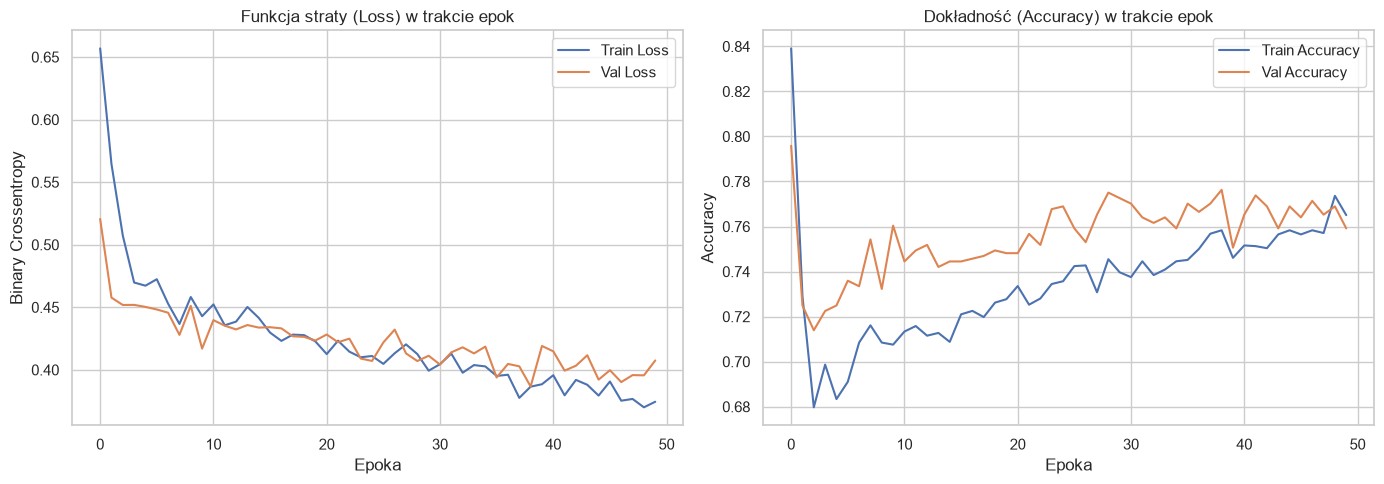

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


,Model,Accuracy,Precision (Udar),Recall (Wykrywalność udaru),F1-Score
0,Płytka Sieć Neuronowa (MLP),0.7476,0.1364,0.78,0.2321
1,Drzewo Decyzyjne (max_depth=5),0.7387,0.1322,0.78,0.2261
2,Naiwny Bayes (GaussianNB),0.3620,0.0700,0.98,0.1307


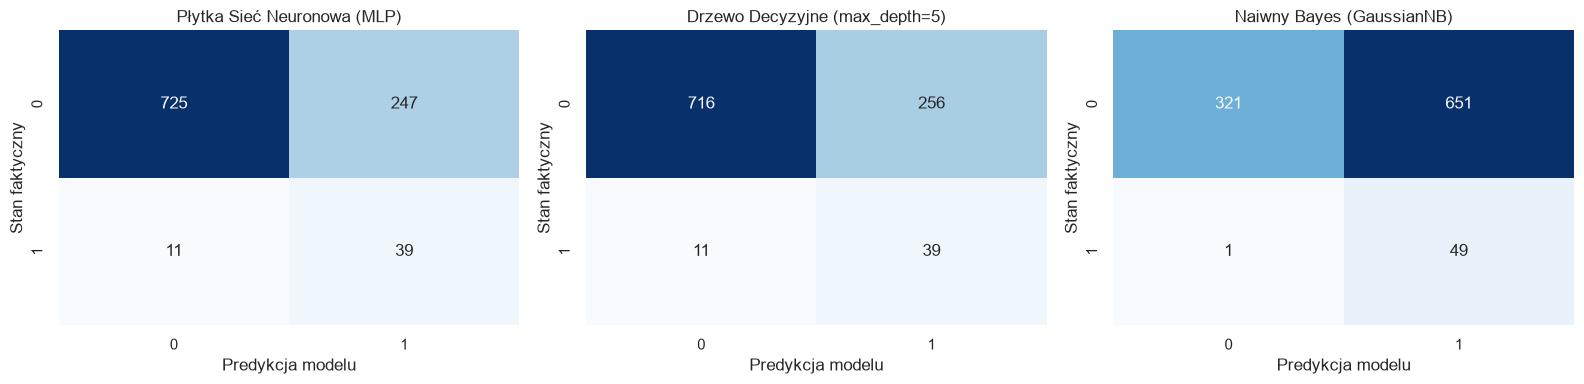

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Wykresy przebiegu uczenia sieci MLP
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Funkcja straty (Loss) w trakcie epok")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Dokładność (Accuracy) w trakcie epok")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Predykcje dla sieci MLP (próg decyzyjny 0.5)
y_pred_mlp = (model_mlp.predict(X_test) > 0.5).astype(int).flatten()

# 3. Trening i predykcje: Drzewo Decyzyjne (z balansem klas i ograniczoną głębokością)
dt_model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# 4. Trening i predykcje: Naiwny Klasyfikator Bayesa
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

# 5. Tabela porównawcza wszystkich 3 modeli
models_preds = {
    "Płytka Sieć Neuronowa (MLP)": y_pred_mlp,
    "Drzewo Decyzyjne (max_depth=5)": y_pred_dt,
    "Naiwny Bayes (GaussianNB)": y_pred_nb
}

results = []
for name, preds in models_preds.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (Udar)": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall (Wykrywalność udaru)": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

# 6. Macierze pomyłek (Confusion Matrices) dla wszystkich modeli
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, preds) in zip(axes, models_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predykcja modelu")
    ax.set_ylabel("Stan faktyczny")

plt.tight_layout()
plt.show()